# Political Interview Response Clarity Classification

University project (Artificial Intelligence course).

Each sample is a question from a presidential press conference and the answer that was given.
The goal is to classify the answer into one of three classes:

- **Clear Reply** – the answer clearly gives the requested information
- **Ambivalent** – the answer is vague or only partly answers the question
- **Clear Non-Reply** – the answer clearly avoids the question

Dataset: [QEvasion](https://huggingface.co/datasets/ailsntua/QEvasion) (Hugging Face).

Approach: text cleaning → TF-IDF and Word2Vec features → Logistic Regression,
compared with **macro F1** against a simple majority-class baseline.

In [1]:
# Εισαγωγή βασικών βιβλιοθηκών
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
import os

from datasets import load_dataset
from sklearn.model_selection import GroupShuffleSplit, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score, ConfusionMatrixDisplay
from gensim.models import Word2Vec

# Για αναπαραγωγιμότητα
RANDOM_STATE = 42

Matplotlib is building the font cache; this may take a moment.


## 1. Data loading & exploration

In [2]:
# Φόρτωση dataset από το Hugging Face
dataset = load_dataset('ailsntua/QEvasion')
df_train = dataset['train'].to_pandas()
df_test = dataset['test'].to_pandas()

print("Train shape:", df_train.shape)
print("Test shape:", df_test.shape)

Train shape: (3448, 20)
Test shape: (308, 20)


In [3]:
print("Στήλες train set:")
print(df_train.columns.tolist())
print("\nΠρώτες 5 γραμμές:")
df_train[['question', 'interview_answer', 'clarity_label']].head()

Στήλες train set:
['title', 'date', 'president', 'url', 'question_order', 'interview_question', 'interview_answer', 'gpt3.5_summary', 'gpt3.5_prediction', 'question', 'annotator_id', 'annotator1', 'annotator2', 'annotator3', 'inaudible', 'multiple_questions', 'affirmative_questions', 'index', 'clarity_label', 'evasion_label']

Πρώτες 5 γραμμές:


,question,interview_answer,clarity_label
0,How would you respond to the accusation that t...,"Well, look, first of all, theI am sincere abou...",Clear Reply
1,Do you think President Xi is being sincere abo...,"Well, look, first of all, theI am sincere abou...",Ambivalent
2,Do you believe the country's slowdown and gro...,"Look, I think China has a difficult economic p...",Ambivalent
3,Are you worried about the meeting between Pre...,"Look, I think China has a difficult economic p...",Ambivalent
4,Is the President's engagement with Asian coun...,"Well, I hope I get to see Mr. Xi sooner than l...",Clear Reply


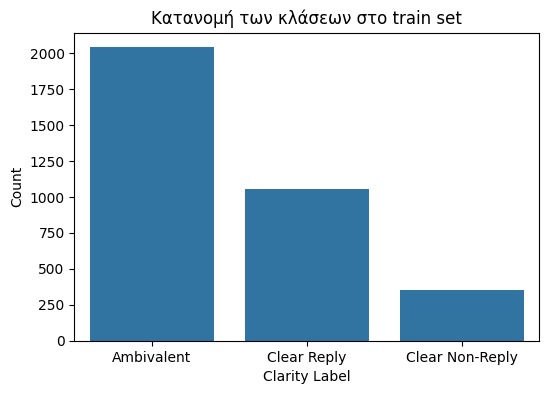

clarity_label
Ambivalent         2040
Clear Reply        1052
Clear Non-Reply     356
Name: count, dtype: int64


In [4]:
# Κατανομή της μεταβλητής-στόχου
plt.figure(figsize=(6,4))
sns.countplot(data=df_train, x='clarity_label', order=df_train['clarity_label'].value_counts().index)
plt.title('Κατανομή των κλάσεων στο train set')
plt.xlabel('Clarity Label')
plt.ylabel('Count')
plt.show()

print(df_train['clarity_label'].value_counts())

Οι κλάσεις δεν είναι ισορροπημένες: το *Ambivalent* είναι περίπου το 59% των δειγμάτων.
Γι' αυτό παρακάτω τα μοντέλα συγκρίνονται με **macro F1** και όχι μόνο με accuracy.

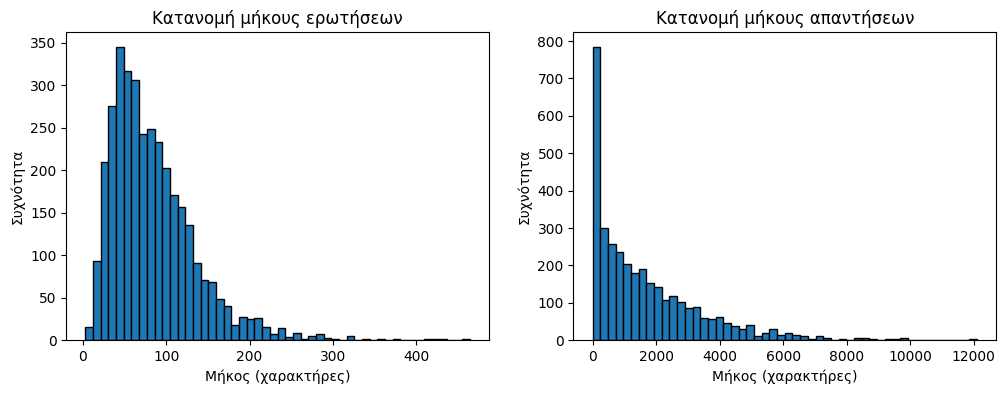

Στατιστικά μήκους ερωτήσεων:
 count    3448.000000
mean       84.496520
std        51.866675
min         3.000000
25%        47.000000
50%        74.000000
75%       110.000000
max       464.000000
Name: question_len, dtype: float64

Στατιστικά μήκους απαντήσεων:
 count     3448.000000
mean      1663.320476
std       1733.344026
min          3.000000
25%        309.000000
50%       1155.500000
75%       2495.000000
max      12102.000000
Name: answer_len, dtype: float64


In [5]:
# Υπολογισμός μηκών
df_train['question_len'] = df_train['question'].astype(str).apply(len)
df_train['answer_len'] = df_train['interview_answer'].astype(str).apply(len)

# Ιστογράμματα
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].hist(df_train['question_len'], bins=50, edgecolor='black')
axes[0].set_title('Κατανομή μήκους ερωτήσεων')
axes[0].set_xlabel('Μήκος (χαρακτήρες)')
axes[0].set_ylabel('Συχνότητα')

axes[1].hist(df_train['answer_len'], bins=50, edgecolor='black')
axes[1].set_title('Κατανομή μήκους απαντήσεων')
axes[1].set_xlabel('Μήκος (χαρακτήρες)')
axes[1].set_ylabel('Συχνότητα')
plt.show()

print("Στατιστικά μήκους ερωτήσεων:\n", df_train['question_len'].describe())
print("\nΣτατιστικά μήκους απαντήσεων:\n", df_train['answer_len'].describe())

In [6]:
print("Missing values ανά στήλη (μόνο όσες χρησιμοποιούμε):")
print(df_train[['question', 'interview_answer', 'clarity_label']].isnull().sum())

Missing values ανά στήλη (μόνο όσες χρησιμοποιούμε):
question            0
interview_answer    0
clarity_label       0
dtype: int64


In [7]:
# Εμφάνιση μερικών παραδειγμάτων
for i in range(3):
    print(f"\n--- Παράδειγμα {i+1} ---")
    print("Ερώτηση:", df_train['question'].iloc[i])
    print("Απάντηση:", df_train['interview_answer'].iloc[i][:500] + "...")
    print("Ετικέτα:", df_train['clarity_label'].iloc[i])


--- Παράδειγμα 1 ---
Ερώτηση: How would you respond to the accusation that the United States is containing China while pushing for diplomatic talks?
Απάντηση: Well, look, first of all, theI am sincere about getting the relationship right. And one of the things that is going on now is, China is beginning to change some of the rules of the game, in terms of trade and other issues.And so one of the things we talked about, for example, is that they're now talking about making sure that no Chineseno one in the Chinese Government can use a Western cell phone. Those kinds of things.And so, really, what this trip was aboutit was less about containing China. I...
Ετικέτα: Clear Reply

--- Παράδειγμα 2 ---
Ερώτηση: Do you think President Xi is being sincere about getting the relationship back on track as he bans Apple in China?
Απάντηση: Well, look, first of all, theI am sincere about getting the relationship right. And one of the things that is going on now is, China is beginning to change som

## 2. Text preprocessing

In [8]:
def clean_text(text):
    """Καθαρισμός κειμένου: πεζά, αφαίρεση σημείων στίξης, αριθμών, πολλαπλών κενών."""
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(f'[{re.escape(string.punctuation)}]', '', text)  # αφαίρεση στίξης
    text = re.sub(r'\d+', '', text)                               # αφαίρεση αριθμών
    text = re.sub(r'\s+', ' ', text).strip()                      # καθαρισμός κενών
    return text

In [9]:
# Καθαρισμός και ένωση ερώτησης + απάντησης σε ένα κείμενο
for df in [df_train, df_test]:
    df['clean_question'] = df['question'].apply(clean_text)
    df['clean_answer'] = df['interview_answer'].apply(clean_text)
    df['text'] = df['clean_question'] + " [SEP] " + df['clean_answer']

# Επιβεβαίωση
print(df_train[['question', 'text']].head(3))

                                            question  \
0  How would you respond to the accusation that t...   
1  Do you think President Xi is being sincere abo...   
2   Do you believe the country's slowdown and gro...   

                                                text  
0  how would you respond to the accusation that t...  
1  do you think president xi is being sincere abo...  
2  do you believe the countrys slowdown and growt...  


## 3. Train / validation split

Η ίδια απάντηση εμφανίζεται σε πολλές γραμμές (μία για κάθε υπο-ερώτηση).
Με απλό τυχαίο split ένα κομμάτι της θα έπεφτε στο train και άλλο στο validation,
και τα αποτελέσματα θα έβγαιναν πιο αισιόδοξα. Γι' αυτό χρησιμοποιούμε `GroupShuffleSplit`,
ώστε κάθε απάντηση να βρίσκεται ολόκληρη **ή** στο train **ή** στο validation.

In [10]:
X = df_train['text']
y = df_train['clarity_label']
groups = df_train['interview_answer']

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, val_idx = next(gss.split(X, y, groups))

X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

print(f"Train size: {len(X_train)}")
print(f"Validation size: {len(X_val)}")
print("Κατανομή validation:\n", y_val.value_counts())

Train size: 2743
Validation size: 705
Κατανομή validation:
 clarity_label
Ambivalent         445
Clear Reply        185
Clear Non-Reply     75
Name: count, dtype: int64


## 4. TF-IDF + Logistic Regression

In [11]:
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1,2), stop_words='english')
X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)

**Baseline:** ένα μοντέλο που προβλέπει πάντα τη συχνότερη κλάση (*Ambivalent*).
Κάθε μοντέλο μας πρέπει να το ξεπερνάει, αλλιώς δεν έχει μάθει κάτι χρήσιμο.

In [12]:
# Απλό baseline: προβλέπει πάντα τη συχνότερη κλάση (Ambivalent)
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train_tfidf, y_train)
y_pred_dummy = dummy.predict(X_val_tfidf)

print("Baseline accuracy:", round(accuracy_score(y_val, y_pred_dummy), 3))
print("Baseline macro F1:", round(f1_score(y_val, y_pred_dummy, average='macro'), 3))

Baseline accuracy: 0.631
Baseline macro F1: 0.258


In [13]:
lr_tfidf = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
lr_tfidf.fit(X_train_tfidf, y_train)

y_pred_tfidf = lr_tfidf.predict(X_val_tfidf)
print("TF-IDF (απλό) – Αποτελέσματα validation:")
print(classification_report(y_val, y_pred_tfidf))

TF-IDF (απλό) – Αποτελέσματα validation:
                 precision    recall  f1-score   support

     Ambivalent       0.65      0.87      0.74       445
Clear Non-Reply       0.70      0.09      0.16        75
    Clear Reply       0.32      0.17      0.22       185

       accuracy                           0.60       705
      macro avg       0.56      0.38      0.38       705
   weighted avg       0.57      0.60      0.54       705



**Grid search:** δοκιμάζουμε διαφορετικό `C` (πόσο ισχυρή είναι η regularization) και
`class_weight='balanced'`, που δίνει μεγαλύτερο βάρος στις μικρές κλάσεις ώστε το μοντέλο
να μην προβλέπει σχεδόν πάντα *Ambivalent*. Κριτήριο: macro F1 με 5-fold cross-validation.

In [14]:
param_grid = {'C': [0.1, 1, 10], 'class_weight': [None, 'balanced']}
grid_tfidf = GridSearchCV(LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
                          param_grid, cv=5, scoring='f1_macro')
grid_tfidf.fit(X_train_tfidf, y_train)

print("Βέλτιστες παράμετροι:", grid_tfidf.best_params_)
best_lr_tfidf = grid_tfidf.best_estimator_
y_pred_tfidf_best = best_lr_tfidf.predict(X_val_tfidf)
print("\nTF-IDF (βελτιστοποιημένο) – Αποτελέσματα validation:")
print(classification_report(y_val, y_pred_tfidf_best))

Βέλτιστες παράμετροι: {'C': 1, 'class_weight': 'balanced'}

TF-IDF (βελτιστοποιημένο) – Αποτελέσματα validation:
                 precision    recall  f1-score   support

     Ambivalent       0.67      0.57      0.62       445
Clear Non-Reply       0.34      0.49      0.40        75
    Clear Reply       0.30      0.36      0.33       185

       accuracy                           0.50       705
      macro avg       0.44      0.47      0.45       705
   weighted avg       0.54      0.50      0.52       705



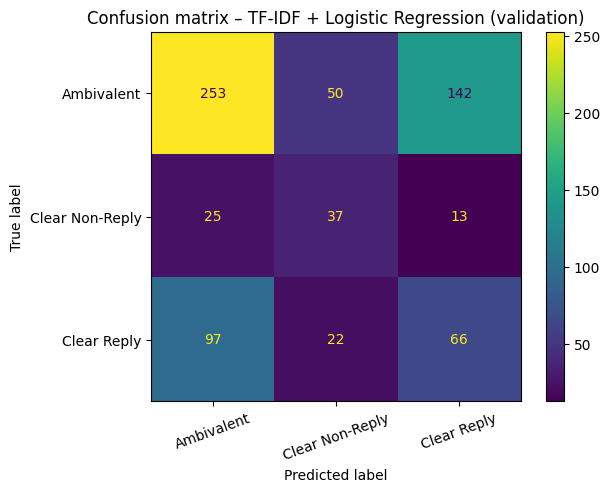

In [15]:
# Ποιες κλάσεις μπερδεύει το μοντέλο μεταξύ τους
ConfusionMatrixDisplay.from_predictions(y_val, y_pred_tfidf_best, xticks_rotation=20)
plt.title('Confusion matrix – TF-IDF + Logistic Regression (validation)')
plt.show()

## 5. Word2Vec + Logistic Regression

In [16]:
# Το Word2Vec εκπαιδεύεται ΜΟΝΟ στο train, ώστε το validation να μείνει "άγνωστο" (χωρίς data leakage)
tokenized_sentences = [text.split() for text in X_train]

w2v_model = Word2Vec(sentences=tokenized_sentences,
                     vector_size=100,
                     window=5,
                     min_count=2,
                     workers=1,
                     seed=RANDOM_STATE)
vector_size = w2v_model.wv.vector_size
print(f"Word2Vec εκπαιδεύτηκε, διάσταση διανυσμάτων: {vector_size}")

Word2Vec εκπαιδεύτηκε, διάσταση διανυσμάτων: 100


In [17]:
def document_vector(doc, model, vector_size):
    """Υπολογίζει το μέσο όρο των word vectors για ένα κείμενο."""
    words = doc.split()
    valid_words = [word for word in words if word in model.wv.key_to_index]
    if len(valid_words) == 0:
        return np.zeros(vector_size)
    return np.mean(model.wv[valid_words], axis=0)

In [18]:
X_train_w2v = np.array([document_vector(doc, w2v_model, vector_size) for doc in X_train])
X_val_w2v = np.array([document_vector(doc, w2v_model, vector_size) for doc in X_val])

print("Train features shape:", X_train_w2v.shape)
print("Validation features shape:", X_val_w2v.shape)

Train features shape: (2743, 100)
Validation features shape: (705, 100)


In [19]:
lr_w2v = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
lr_w2v.fit(X_train_w2v, y_train)

y_pred_w2v = lr_w2v.predict(X_val_w2v)
print("Word2Vec – Αποτελέσματα validation:")
print(classification_report(y_val, y_pred_w2v))

Word2Vec – Αποτελέσματα validation:
                 precision    recall  f1-score   support

     Ambivalent       0.66      0.93      0.77       445
Clear Non-Reply       0.42      0.17      0.25        75
    Clear Reply       0.36      0.08      0.12       185

       accuracy                           0.63       705
      macro avg       0.48      0.39      0.38       705
   weighted avg       0.55      0.63      0.55       705



In [20]:
param_grid_w2v = {'C': [0.1, 1, 10], 'class_weight': [None, 'balanced']}
grid_w2v = GridSearchCV(LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
                        param_grid_w2v, cv=5, scoring='f1_macro')
grid_w2v.fit(X_train_w2v, y_train)

print("Βέλτιστες παράμετροι για Word2Vec:", grid_w2v.best_params_)
best_lr_w2v = grid_w2v.best_estimator_
y_pred_w2v_best = best_lr_w2v.predict(X_val_w2v)
print("\nWord2Vec (βελτιστοποιημένο) – Αποτελέσματα validation:")
print(classification_report(y_val, y_pred_w2v_best))

Βέλτιστες παράμετροι για Word2Vec: {'C': 10, 'class_weight': 'balanced'}

Word2Vec (βελτιστοποιημένο) – Αποτελέσματα validation:
                 precision    recall  f1-score   support

     Ambivalent       0.69      0.59      0.63       445
Clear Non-Reply       0.25      0.61      0.36        75
    Clear Reply       0.34      0.25      0.29       185

       accuracy                           0.50       705
      macro avg       0.42      0.49      0.43       705
   weighted avg       0.55      0.50      0.51       705



## 6. Comparison on the validation set

In [21]:
# Συγκεντρωτικός πίνακας
results = {
    'Majority class (always "Ambivalent")': y_pred_dummy,
    'TF-IDF + LR': y_pred_tfidf,
    'TF-IDF + LR (tuned)': y_pred_tfidf_best,
    'Word2Vec + LR': y_pred_w2v,
    'Word2Vec + LR (tuned)': y_pred_w2v_best,
}
summary = pd.DataFrame({
    'Accuracy': [accuracy_score(y_val, p) for p in results.values()],
    'Macro F1': [f1_score(y_val, p, average='macro') for p in results.values()],
}, index=results.keys()).round(3)
summary

,Accuracy,Macro F1
"Majority class (always ""Ambivalent"")",0.631,0.258
TF-IDF + LR,0.603,0.376
TF-IDF + LR (tuned),0.505,0.448
Word2Vec + LR,0.628,0.380
Word2Vec + LR (tuned),0.504,0.426


## 7. Final model & test set

In [22]:
# Επιλέγουμε το βελτιστοποιημένο TF-IDF (καλύτερο macro F1)
# Εκπαιδεύουμε ξανά σε όλο το train set (train + validation)
X_all = df_train['text']
y_all = df_train['clarity_label']

tfidf_final = TfidfVectorizer(max_features=5000, ngram_range=(1,2), stop_words='english')
X_all_tfidf = tfidf_final.fit_transform(X_all)

# Παίρνουμε τις παραμέτρους που βρήκε το grid search (όχι σταθερές τιμές)
lr_final = LogisticRegression(**grid_tfidf.best_params_, random_state=RANDOM_STATE, max_iter=1000)
lr_final.fit(X_all_tfidf, y_all)

print("Τελικό μοντέλο εκπαιδεύτηκε σε όλα τα δεδομένα με:", grid_tfidf.best_params_)

Τελικό μοντέλο εκπαιδεύτηκε σε όλα τα δεδομένα με: {'C': 1, 'class_weight': 'balanced'}


In [23]:
X_test = df_test['text']
X_test_tfidf = tfidf_final.transform(X_test)
y_test_pred = lr_final.predict(X_test_tfidf)

print("Κατανομή προβλέψεων στο test set:")
print(pd.Series(y_test_pred).value_counts())

Κατανομή προβλέψεων στο test set:
Ambivalent         161
Clear Reply        113
Clear Non-Reply     34
Name: count, dtype: int64


In [24]:
# Το test set έχει ετικέτες, οπότε βγάζουμε και το τελικό αποτέλεσμα
# (δεν χρησιμοποιήθηκε σε καμία απόφαση, άρα είναι η πιο "τίμια" εκτίμηση)
if df_test['clarity_label'].notna().all():
    print("Test set – τελικά αποτελέσματα:")
    print(classification_report(df_test['clarity_label'], y_test_pred))
    print("Test macro F1:", round(f1_score(df_test['clarity_label'], y_test_pred, average='macro'), 3))
else:
    print("Το test set δεν έχει ετικέτες")

Test set – τελικά αποτελέσματα:
                 precision    recall  f1-score   support

     Ambivalent       0.71      0.56      0.63       206
Clear Non-Reply       0.32      0.48      0.39        23
    Clear Reply       0.27      0.38      0.31        79

       accuracy                           0.51       308
      macro avg       0.43      0.47      0.44       308
   weighted avg       0.57      0.51      0.53       308

Test macro F1: 0.442


In [25]:
# Δημιουργία αρχείου submission (το test set έχει 308 γραμμές)
submission = pd.DataFrame({
    'Id': range(len(y_test_pred)),
    'Predicted': y_test_pred
})

submission.to_csv('submission.csv', index=False)
print("submission.csv δημιουργήθηκε επιτυχώς!")
print("Διαστάσεις:", submission.shape)

submission.csv δημιουργήθηκε επιτυχώς!
Διαστάσεις: (308, 2)


## 8. Results & conclusions

**Validation set** (705 samples, grouped split by answer):

| Model | Accuracy | Macro F1 |
|---|---|---|
| Majority class (always "Ambivalent") | 0.631 | 0.258 |
| TF-IDF + Logistic Regression | 0.603 | 0.376 |
| Word2Vec + Logistic Regression | 0.628 | 0.380 |
| Word2Vec + Logistic Regression (tuned) | 0.504 | 0.426 |
| **TF-IDF + Logistic Regression (tuned)** | 0.505 | **0.448** |

**Test set** (308 samples, final TF-IDF model): accuracy **0.51**, macro F1 **0.44**.

**Conclusions**

- Accuracy is misleading here: always predicting "Ambivalent" already gives 0.63, but it never finds the other two classes (macro F1 0.26). That is why the models are compared with macro F1.
- `class_weight='balanced'` was chosen by the grid search for both feature types. Accuracy drops, but the small classes are predicted much better, so macro F1 goes up (0.38 → 0.45 for TF-IDF).
- TF-IDF with bigrams is slightly better than averaged Word2Vec vectors. Averaging over long answers loses detail, and Word2Vec is trained on only ~2,700 texts.
- The hardest class is **Clear Reply** (F1 ≈ 0.33): it is mostly confused with Ambivalent (see the confusion matrix). The difference between the two is often about meaning, not specific words.
- The validation and test scores are close (0.45 vs 0.44), so the grouped split gives a realistic estimate.

**Possible improvements:** a pretrained transformer model (e.g. BERT) that can model the relation between the question and the answer, not only the words used.